# **01 - Data Cleaning & EDA**

## **0. About the dataset**

**Source:** Rossmann Store Sales (Kaggle). Rossmann is a drug store chain in Germany.

**Files used:** `train.csv` (daily sales per store) and `store.csv` (store characteristics), merged on `Store`. `test.csv` was not used because it has no `Sales` column.

**Size:** 1,017,209 rows (daily records) for 1,115 stores, from 2013-01-01 to 2015-07-31.

**Goal:** predict daily `Sales` per store.

### Columns

| Column | Source | Description |
|---|---|---|
| Store | both | Store ID |
| DayOfWeek | train | Day of the week (1 = Monday) |
| Date | train | Date of the record |
| Sales | train | Daily turnover (**target**) |
| Customers | train | Number of customers that day |
| Open | train | 1 = store open, 0 = closed |
| Promo | train | 1 = store running a promotion that day |
| StateHoliday | train | Public holiday type (0 = none, a/b/c = holiday types) |
| SchoolHoliday | train | 1 = affected by public school closure |
| StoreType | store | Store model (a, b, c, d) |
| Assortment | store | Product range level (a = basic, b = extra, c = extended) |
| CompetitionDistance | store | Distance in meters to the nearest competitor |
| CompetitionOpenSinceMonth/Year | store | When the nearest competitor opened |
| Promo2 | store | 1 = store takes part in a continuing promotion |
| Promo2SinceWeek/Year | store | When the store joined Promo2 |
| PromoInterval | store | Months when Promo2 restarts |

## **1. Loading and merging**

In [96]:
import warnings 
warnings.filterwarnings("ignore")

In [97]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [98]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

In [99]:
train = pd.read_csv("../data/raw/train.csv", low_memory=False)
store = pd.read_csv("../data/raw/store.csv")

In [100]:
print(train.shape, store.shape)

(1017209, 9) (1115, 10)


### **Raw data overview**
- `train`: 1,017,209 rows x 9 columns. One row per store per day (942 days per store).
- `store`: 1,115 rows x 10 columns. One row per store.

In [101]:
train.head(20)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
5,6,5,2015-07-31,5651,589,1,1,0,1
6,7,5,2015-07-31,15344,1414,1,1,0,1
7,8,5,2015-07-31,8492,833,1,1,0,1
8,9,5,2015-07-31,8565,687,1,1,0,1
9,10,5,2015-07-31,7185,681,1,1,0,1


In [102]:
store.head(20)

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
5,6,a,a,310.0,12.0,2013.0,0,NaN,NaN,NaN
6,7,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
7,8,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
8,9,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
9,10,a,a,3160.0,9.0,2009.0,0,NaN,NaN,NaN


In [103]:
print(store["Store"].is_unique)

True


### **Checking the merge key**
`Store` is unique in `store.csv` (`True`), so each store has exactly one row of characteristics. In `train`, each store appears once per day. A left merge therefore adds columns without duplicating or dropping any sales rows.

In [104]:
print(train["Store"].value_counts().head())


Store
1115    942
1       942
2       942
3       942
4       942
Name: count, dtype: int64


In [105]:
train[train["Store"] == 1].head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1115,1,4,2015-07-30,5020,546,1,1,0,1
2230,1,3,2015-07-29,4782,523,1,1,0,1
3345,1,2,2015-07-28,5011,560,1,1,0,1
4460,1,1,2015-07-27,6102,612,1,1,0,1


### **Merge**
`train` and `store` are merged on `Store` with `how="left"`, so all sales rows are kept. Check: the row count is unchanged (1,017,209) and the result has 18 columns.

In [106]:
df = train.merge(store, on="Store", how="left")
print(df.shape)
print(len(df) == len(train))

(1017209, 18)
True


## **2. Initial inspection**
Data types, summary statistics and missing values of the merged data.

In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  object 
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  object 
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  object 
 10  Assortment                 1017209 non-null  object 
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionO

In [108]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Store,1017209.0,NaN,NaN,NaN,558.429727,321.908651,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,NaN,NaN,NaN,3.998341,1.997391,1.0,2.0,4.0,6.0,7.0
Date,1017209,942,2013-01-02,1115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales,1017209.0,NaN,NaN,NaN,5773.818972,3849.926175,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,NaN,NaN,NaN,633.145946,464.411734,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,NaN,NaN,NaN,0.830107,0.375539,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,NaN,NaN,NaN,0.381515,0.485759,0.0,0.0,0.0,1.0,1.0
StateHoliday,1017209,4,0,986159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SchoolHoliday,1017209.0,NaN,NaN,NaN,0.178647,0.383056,0.0,0.0,0.0,0.0,1.0
StoreType,1017209,4,a,551627,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [109]:
df.isna().sum()

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64

### **Findings before cleaning**
| Column | Missing | Likely reason |
|---|---|---|
| CompetitionDistance | 2,642 rows (3 stores) | no competitor distance recorded |
| CompetitionOpenSinceMonth/Year | 323,348 (~32%) | competitor open date unknown |
| Promo2SinceWeek/Year, PromoInterval | 508,031 (~50%) | store does not take part in Promo2 |

Other observations:
- `Date` is stored as text (`object`) and must be converted.
- `Open` has a mean of 0.83, so ~17% of rows are closed days with zero sales.
- `CompetitionOpenSinceYear` has a minimum of 1900, which looks unusual. It was left unchanged, but it needs care if used to compute competition duration.

## **3. Date conversion and sorting**
`Date` was converted to datetime (range: 2013-01-01 to 2015-07-31). The data is sorted by `Store` then `Date`, which is required for lag and rolling features so that the previous row is always the previous day of the same store.

In [110]:
df["Date"] = pd.to_datetime(df["Date"])
print(df["Date"].min(), df["Date"].max())

2013-01-01 00:00:00 2015-07-31 00:00:00


In [111]:
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)

## **4. Closed days**
- 172,817 rows are closed days (`Open == 0`) and 54 rows are open days with zero sales.
- Both were removed. A closed store has zero sales because it is closed, not because demand is low, and zero sales would break MAPE.
- The `Open` column was dropped afterwards since it is constant (always 1).
- Result: 844,338 rows x 17 columns.

In [112]:
print("closed days:", (df["Open"] == 0).sum())

closed days: 172817


In [113]:
print("open but zero sales:", ((df["Open"] == 1) & (df["Sales"] == 0)).sum())

open but zero sales: 54


In [114]:
df = df[(df["Open"] == 1) & (df["Sales"] > 0)].copy()
df = df.drop(columns=["Open"])
print(df.shape)

(844338, 17)


## **5. Missing values**
| Column | Treatment | Reason |
|---|---|---|
| CompetitionDistance | median | only 3 stores, and the median is robust to very large distances |
| CompetitionOpenSinceMonth/Year | 0 + flag `HasCompetitionDate` | open date unknown, not an error |
| Promo2SinceWeek/Year | 0 | store is not in Promo2 |
| PromoInterval | "None" | store is not in Promo2 |

In [115]:
df["CompetitionDistance"] = df["CompetitionDistance"].fillna(df["CompetitionDistance"].median())

In [116]:
df["HasCompetitionDate"] = df["CompetitionOpenSinceYear"].notna().astype(int)

The flag is created **before** `fillna(0)`, because it relies on the values still being missing. It lets the model tell "date unknown" apart from a real value.

In [117]:
df["CompetitionOpenSinceMonth"]=df["CompetitionOpenSinceMonth"].fillna(0)
df["CompetitionOpenSinceYear"]=df["CompetitionOpenSinceYear"].fillna(0)

In [118]:
df["Promo2SinceWeek"] = df["Promo2SinceWeek"].fillna(0)
df["Promo2SinceYear"] = df["Promo2SinceYear"].fillna(0)
df["PromoInterval"] = df["PromoInterval"].fillna("None")

Check: no missing values remain.

In [119]:
print(df.isna().sum())

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
HasCompetitionDate           0
dtype: int64


## **6. Outliers**
After cleaning, `Sales` has a mean of ~6,956, a median of ~6,369 and a max of 41,551. The mean is above the median, which suggests a right-skewed distribution.

In [120]:
print(df["Sales"].describe())


count    844338.000000
mean       6955.959134
std        3103.815515
min          46.000000
25%        4859.000000
50%        6369.000000
75%        8360.000000
max       41551.000000
Name: Sales, dtype: float64


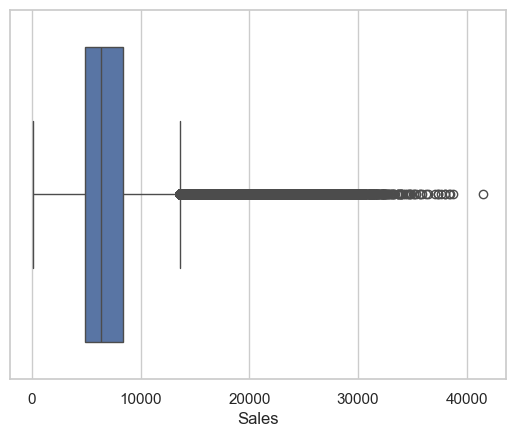

In [121]:
sns.boxplot(x=df["Sales"])
plt.show()

**Method:** the boxplot shows a long tail of high values. However, a single global threshold would mostly flag large stores, not unusual days. Instead, outliers are detected **per store** using the IQR rule: a day is flagged if its sales are above `Q3 + 1.5 x IQR` of its own store.

In [122]:
g = df.groupby("Store")["Sales"]
q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))

In [123]:
df["IsOutlier"] = (df["Sales"] > q3 + 1.5 * (q3 - q1)).astype(int)

In [124]:
n_outliers = df["IsOutlier"].sum()
pct_outliers = df["IsOutlier"].mean() * 100
print(f"Outlier rows: {n_outliers:,} out of {len(df):,} ({pct_outliers:.2f}%)")

Outlier rows: 16,008 out of 844,338 (1.90%)


**Result:** 16,008 rows (1.90%) are flagged in the `IsOutlier` column.

**Decision:** outliers were **kept, not removed or capped**. They are real sales (pre-holiday and promo days), and removing them would make the model unable to predict high-demand days, which matter most for inventory planning.

**Note for feature engineering:** `IsOutlier` is derived from `Sales` (the target), so it must **not** be used as a model feature. It is for analysis and reporting only.

## **7. Export**
Saved to `data/processed/cleaned_data.csv`: 844,338 rows x 19 columns (~69 MB).
- Added columns: `HasCompetitionDate`, `IsOutlier`
- Removed column: `Open`

**Notes for feature engineering:**
- Column names are unchanged (`Store`, `Date`, `Sales`).
- Data is sorted by `Store`, `Date`.
- `Customers` is only known on the day itself, so it must not be used as a feature (data leakage).
- `IsOutlier` must not be used as a feature.
- Closed days were removed, so some stores have gaps in their dates. Lag and rolling features should be built using dates (reindex or merge on date), not a plain `shift`.

In [125]:
df.to_csv("../data/processed/cleaned_data.csv", index=False)

print(df.shape)
print(f"File size: {os.path.getsize('../data/processed/cleaned_data.csv') / 1e6:.1f} MB")

(844338, 19)
File size: 69.1 MB


## **8. Time-oriented EDA: trend, seasonality, holidays**

## **9. Store comparison**